# Part 2: Student-t Innovations vs. Normal Innovations

### Ramith Vaid | NTU Singapore

The README's own "Known Limitations" section flags the **normal-innovations assumption**: the GARCH likelihood assumes normally distributed return shocks, while real returns have fatter tails, and Part 1 left the VaR backtest on a single window. This notebook replaces the normal assumption with Student-t innovations and compares the two models on the same data, two ways:

1. **Model fit.** Full-sample maximum likelihood for GARCH(1,1)-normal vs. GARCH(1,1)-t: log-likelihood, AIC/BIC (the t model has one extra parameter, the degrees of freedom `nu`), a likelihood-ratio test, and the tail behaviour of the standardized residuals.
2. **VaR coverage.** A rolling out-of-sample backtest of one-day 95% and 99% VaR from both models, scored with the Kupiec proportion-of-failures test and the Christoffersen independence and conditional-coverage tests, plus an out-of-sample density score (mean log predictive likelihood).

Everything reuses `garch_utils.py` from Part 1: the normal model is the same `fit_garch` as before, and the t model is new code in the same module (`fit_garch_t`, `garch_t_neg_log_likelihood`), written so that it converges to the normal likelihood as `nu` grows. The Part 1 test window was 250 days, which at the 99% level expects only ~2.5 breaches, far too few for a coverage test to say anything. So the VaR backtest here uses a **750-day test window** and also reports the last 250 days separately so the two windows can be compared.

**Data end date is pinned** (`END = '2026-10-14'`, exclusive, so the last row is 2026-10-13, the same last row Part 1 used) so that this notebook reproduces rather than drifting every day with a live download.

In [1]:
import pandas as pd
import numpy as np
import yfinance as yf
import matplotlib.pyplot as plt
from scipy.stats import kurtosis, chi2
import warnings
warnings.filterwarnings('ignore')

from garch_utils import (
    fit_garch, garch_neg_log_likelihood, fit_garch_t, garch_t_neg_log_likelihood,
    garch_variance_path, standardized_residuals, log_density_normal, log_density_t,
    var_threshold, kupiec_pof, christoffersen, rolling_normal_vs_t
)

print('Libraries loaded.')

Libraries loaded.


## 1. Data Collection (same tickers and range as Part 1, end date pinned)

In [2]:
TICKERS = {'JPM': 'JPMorgan Chase', '^GSPC': 'S&P 500'}
START = '2014-01-01'
END = '2026-10-14'  # exclusive: last row is 2026-10-13, matching the Part 1 run

log_returns = {}
for ticker, name in TICKERS.items():
    df = yf.download(ticker, start=START, end=END, progress=False)
    close = df['Close'].squeeze()
    log_returns[ticker] = np.log(close / close.shift(1)).dropna()
    r = log_returns[ticker]
    print(f'{name} ({ticker}): {len(r)} daily log returns, {r.index[0].date()} to {r.index[-1].date()}')

JPMorgan Chase (JPM): 3213 daily log returns, 2014-01-03 to 2026-10-13
S&P 500 (^GSPC): 3213 daily log returns, 2014-01-03 to 2026-10-13


## 2. Sanity checks on the new code

Two properties the Student-t implementation must satisfy before its numbers are trusted: the vectorised variance recursion must equal the explicit loop used by the Part 1 likelihood, and the t likelihood must converge to the normal likelihood as `nu` grows (the t model nests the normal).

In [3]:
r_test = log_returns['JPM'].values[-750:] * 100
w, a, b = fit_garch(r_test)

sigma2_loop = np.zeros(len(r_test))
sigma2_loop[0] = np.var(r_test)
for t in range(1, len(r_test)):
    sigma2_loop[t] = w + a * r_test[t-1]**2 + b * sigma2_loop[t-1]
print(f'Max |vectorised - loop| conditional variance: {np.abs(sigma2_loop - garch_variance_path(r_test, w, a, b)).max():.2e}')

nll_normal = garch_neg_log_likelihood([w, a, b], r_test)
nll_t_big_nu = garch_t_neg_log_likelihood([w, a, b, 1e6], r_test)
print(f'Normal NLL: {nll_normal:.4f}   t NLL at nu = 1,000,000: {nll_t_big_nu:.4f}   (should agree)')

Max |vectorised - loop| conditional variance: 0.00e+00
Normal NLL: 1329.8723   t NLL at nu = 1,000,000: 1329.8709   (should agree)


## 3. Model fit: full-sample maximum likelihood

Both models are fit on each ticker's full history. AIC = 2k - 2 logL and BIC = k ln(n) - 2 logL, with k = 3 (normal) or 4 (t). The likelihood-ratio statistic is 2 (logL_t - logL_normal); because `nu = infinity` (the normal) sits on the boundary of the t model's parameter space, the p-value uses the standard 50:50 chi-square mixture, i.e. 0.5 * P(chi2_1 > LR).

In [4]:
fit_rows = []
for ticker, name in TICKERS.items():
    r = log_returns[ticker].values * 100
    n = len(r)
    wn, an, bn = fit_garch(r)
    ll_n = -garch_neg_log_likelihood([wn, an, bn], r)
    wt, at, bt, nu = fit_garch_t(r, start=(wn, an, bn))
    ll_t = -garch_t_neg_log_likelihood([wt, at, bt, nu], r)
    lr = 2 * (ll_t - ll_n)
    z_n = standardized_residuals(r, wn, an, bn)
    z_t = standardized_residuals(r, wt, at, bt)
    fit_rows.append({
        'ticker': ticker, 'n': n,
        'alpha_normal': an, 'beta_normal': bn, 'alpha_t': at, 'beta_t': bt, 'nu_hat': nu,
        'logL_normal': ll_n, 'logL_t': ll_t, 'LR': lr, 'LR_p': 0.5 * chi2.sf(max(lr, 0), 1),
        'AIC_normal': 2 * 3 - 2 * ll_n, 'AIC_t': 2 * 4 - 2 * ll_t,
        'BIC_normal': 3 * np.log(n) - 2 * ll_n, 'BIC_t': 4 * np.log(n) - 2 * ll_t,
        'resid_excess_kurt_normal_fit': kurtosis(z_n),
        'resid_excess_kurt_t_fit': kurtosis(z_t),
        'implied_excess_kurt_t': 6 / (nu - 4) if nu > 4 else np.inf,
    })
fit_df = pd.DataFrame(fit_rows).set_index('ticker')

pd.set_option('display.float_format', lambda v: f'{v:,.4f}')
print(fit_df.T.to_string())
print()
for ticker in TICKERS:
    f = fit_df.loc[ticker]
    better_aic = 't' if f['AIC_t'] < f['AIC_normal'] else 'normal'
    better_bic = 't' if f['BIC_t'] < f['BIC_normal'] else 'normal'
    print(f'{ticker}: nu_hat = {f["nu_hat"]:.2f}, LR = {f["LR"]:.1f} (p = {f["LR_p"]:.2g}); '
          f'AIC prefers {better_aic}, BIC prefers {better_bic}; '
          f'standardized-residual excess kurtosis under the normal fit = {f["resid_excess_kurt_normal_fit"]:.2f} (0 for a normal).')

ticker                               JPM       ^GSPC
n                             3,213.0000  3,213.0000
alpha_normal                      0.1037      0.1600
beta_normal                       0.8317      0.8026
alpha_t                           0.1208      0.1614
beta_t                            0.8297      0.8270
nu_hat                            4.6614      5.7778
logL_normal                  -5,728.5484 -4,089.7712
logL_t                       -5,565.8503 -3,993.2653
LR                              325.3962    193.0118
LR_p                              0.0000      0.0000
AIC_normal                   11,463.0968  8,185.5425
AIC_t                        11,139.7006  7,994.5307
BIC_normal                   11,481.3217  8,203.7674
BIC_t                        11,164.0005  8,018.8305
resid_excess_kurt_normal_fit      4.3988      2.3883
resid_excess_kurt_t_fit           4.5505      2.7651
implied_excess_kurt_t             9.0716      3.3749

JPM: nu_hat = 4.66, LR = 325.4 (p = 4.8e-73);

## 4. VaR coverage: rolling out-of-sample backtest

For each of the last 750 trading days, both models are refit on the previous 750 days (the same train window as Part 1) and produce a one-day-ahead conditional variance. A 95% (or 99%) VaR breach is a day whose return falls below `-q * sigma`, where `q` is the normal quantile for the normal model and the unit-variance-rescaled t quantile (using that day's fitted `nu`) for the t model. Zero mean is assumed, as in Part 1.

This is ~1,500 GARCH fits per ticker, so it takes a few minutes.

In [5]:
rolling = {}
for ticker, name in TICKERS.items():
    print(f'Rolling normal + t refits for {name} ({ticker})...')
    rolling[ticker] = rolling_normal_vs_t(log_returns[ticker], train_window=750, test_size=750)
    print(f'  {len(rolling[ticker])} test days, {rolling[ticker].index[0].date()} to {rolling[ticker].index[-1].date()}, '
          f'median fitted nu = {rolling[ticker]["nu"].median():.1f}')

Rolling normal + t refits for JPMorgan Chase (JPM)...


  750 test days, 2023-10-17 to 2026-10-13, median fitted nu = 4.2
Rolling normal + t refits for S&P 500 (^GSPC)...


  750 test days, 2023-10-17 to 2026-10-13, median fitted nu = 8.0


In [6]:
LEVELS = [0.95, 0.99]
WINDOWS = {'last 750 days': 750, 'last 250 days (Part 1 window length)': 250}

var_rows = []
for ticker in TICKERS:
    d = rolling[ticker]
    sig_n, sig_t = np.sqrt(d['sigma2_normal']), np.sqrt(d['sigma2_t'])
    for level in LEVELS:
        p = 1 - level
        thr_n = var_threshold(sig_n, level, 'normal')
        thr_t = var_threshold(sig_t, level, 't', nu=d['nu'])
        for wname, wlen in WINDOWS.items():
            for model, thr in (('normal', thr_n), ('t', thr_t)):
                hits = (d['ret'] < thr).values[-wlen:].astype(int)
                x = int(hits.sum())
                _, p_pof = kupiec_pof(x, len(hits), p)
                c = christoffersen(hits, p)
                var_rows.append({'ticker': ticker, 'level': level, 'window': wname, 'model': model,
                                 'n_days': len(hits), 'breaches': x, 'expected': round(p * len(hits), 1),
                                 'breach_rate_%': 100 * x / len(hits), 'nominal_%': 100 * p,
                                 'kupiec_p': p_pof, 'indep_p': c['p_ind'], 'cond_cov_p': c['p_cc']})
var_df = pd.DataFrame(var_rows)

pd.set_option('display.float_format', lambda v: f'{v:,.3f}')
print(var_df.to_string(index=False))

ticker  level                               window  model  n_days  breaches  expected  breach_rate_%  nominal_%  kupiec_p  indep_p  cond_cov_p
   JPM  0.950                        last 750 days normal     750        31    37.500          4.133      5.000     0.262    0.539       0.442
   JPM  0.950                        last 750 days      t     750        36    37.500          4.800      5.000     0.800    0.833       0.947
   JPM  0.950 last 250 days (Part 1 window length) normal     250        11    12.500          4.400      5.000     0.657    0.313       0.545
   JPM  0.950 last 250 days (Part 1 window length)      t     250        16    12.500          6.400      5.000     0.329    0.138       0.207
   JPM  0.990                        last 750 days normal     750        19     7.500          2.533      1.000     0.000    0.501       0.002
   JPM  0.990                        last 750 days      t     750        17     7.500          2.267      1.000     0.003    0.395       0.008

## 5. Out-of-sample density score

VaR coverage only looks at the tail threshold. The mean log predictive likelihood scores the whole one-day-ahead distribution each model forecast, on the same 750 test days (higher is better). The difference is t minus normal, in log-likelihood units per day.

In [7]:
score_rows = []
for ticker in TICKERS:
    d = rolling[ticker]
    ls_n = log_density_normal(d['ret'].values, d['sigma2_normal'].values)
    ls_t = log_density_t(d['ret'].values, d['sigma2_t'].values, d['nu'].values)
    diff = ls_t - ls_n
    score_rows.append({'ticker': ticker, 'mean_logscore_normal': ls_n.mean(), 'mean_logscore_t': ls_t.mean(),
                       'diff_t_minus_normal': diff.mean(), 'diff_se': diff.std(ddof=1) / np.sqrt(len(diff)),
                       'share_days_t_better_%': 100 * (diff > 0).mean(),
                       'median_nu': d['nu'].median(), 'min_nu': d['nu'].min(), 'max_nu': d['nu'].max()})
score_df = pd.DataFrame(score_rows).set_index('ticker')
print(score_df.T.to_string())
print()
for ticker in TICKERS:
    s = score_df.loc[ticker]
    t_stat = s['diff_t_minus_normal'] / s['diff_se']
    print(f'{ticker}: mean log score difference (t - normal) = {s["diff_t_minus_normal"]:+.4f} per day '
          f'(t-statistic {t_stat:+.1f}); t is better on {s["share_days_t_better_%"]:.0f}% of days.')

ticker                   JPM  ^GSPC
mean_logscore_normal  -1.785 -1.260
mean_logscore_t       -1.700 -1.231
diff_t_minus_normal    0.085  0.029
diff_se                0.039  0.011
share_days_t_better_% 60.000 61.200
median_nu              4.164  7.953
min_nu                 3.737  5.412
max_nu                 7.537 27.641

JPM: mean log score difference (t - normal) = +0.0851 per day (t-statistic +2.2); t is better on 60% of days.
^GSPC: mean log score difference (t - normal) = +0.0292 per day (t-statistic +2.7); t is better on 61% of days.


## 6. Chart: breach rates and the fitted degrees of freedom

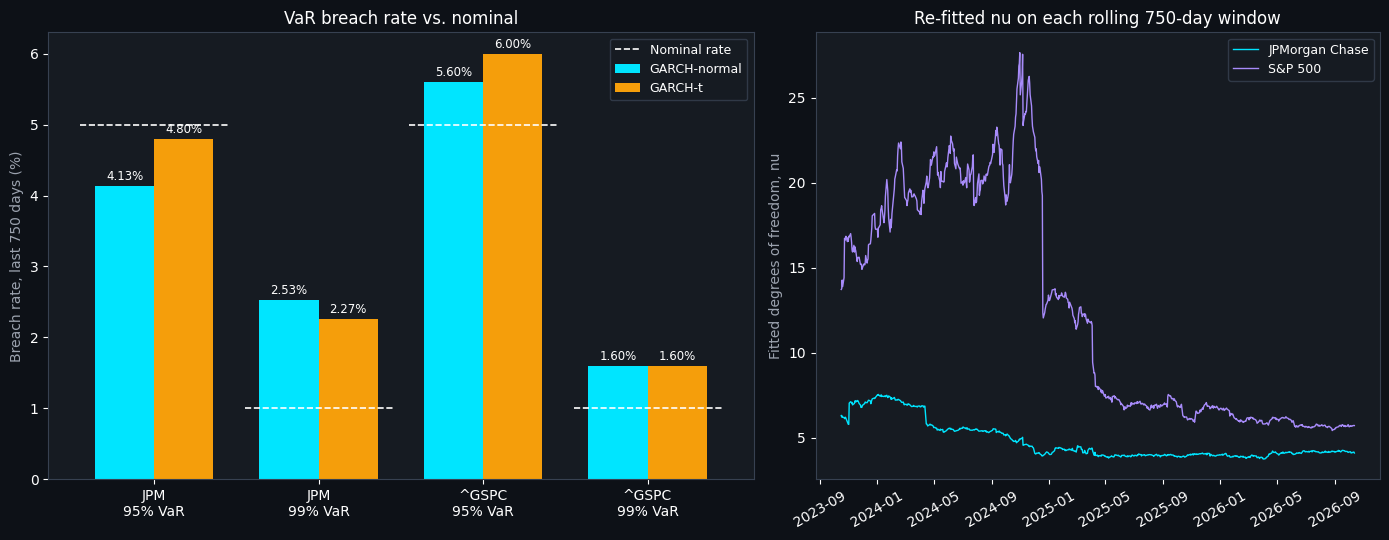

Saved chart_part2_student_t.png


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), gridspec_kw={'width_ratios': [1.25, 1]})
fig.patch.set_facecolor('#0d1117')
for ax in axes:
    ax.set_facecolor('#161b22')
    ax.tick_params(colors='white')
    for spine in ax.spines.values():
        spine.set_edgecolor('#374151')

# Left: breach rate vs. nominal, last 750 days
ax = axes[0]
groups = [(t, l) for t in TICKERS for l in LEVELS]
sub = var_df[var_df['window'] == 'last 750 days']
x = np.arange(len(groups))
width = 0.36
for off, model, color, label in ((-width/2, 'normal', '#00e5ff', 'GARCH-normal'), (width/2, 't', '#f59e0b', 'GARCH-t')):
    vals = [sub[(sub.ticker == t) & (sub.level == l) & (sub.model == model)]['breach_rate_%'].iloc[0] for t, l in groups]
    bars = ax.bar(x + off, vals, width, color=color, label=label)
    for b, v in zip(bars, vals):
        ax.text(b.get_x() + b.get_width()/2, v + 0.08, f'{v:.2f}%', ha='center', fontsize=8.5, color='white')
for xi, (t, l) in zip(x, groups):
    ax.hlines(100 * (1 - l), xi - 0.45, xi + 0.45, colors='white', linestyles='--', linewidth=1.2,
              label='Nominal rate' if xi == 0 else None)
ax.set_xticks(x)
ax.set_xticklabels([f'{t}\n{int(l*100)}% VaR' for t, l in groups], color='white')
ax.set_ylabel('Breach rate, last 750 days (%)', color='#9ca3af')
ax.set_title('VaR breach rate vs. nominal', color='white', fontsize=12)
ax.legend(facecolor='#161b22', edgecolor='#374151', labelcolor='white', fontsize=9)

# Right: fitted nu over the test window
ax = axes[1]
colors_map = {'JPM': '#00e5ff', '^GSPC': '#a78bfa'}
for ticker, name in TICKERS.items():
    ax.plot(rolling[ticker].index, rolling[ticker]['nu'], color=colors_map[ticker], linewidth=1, label=name)
ax.set_ylabel('Fitted degrees of freedom, nu', color='#9ca3af')
ax.set_title('Re-fitted nu on each rolling 750-day window', color='white', fontsize=12)
ax.legend(facecolor='#161b22', edgecolor='#374151', labelcolor='white', fontsize=9)
for lab in ax.get_xticklabels():
    lab.set_rotation(30)

plt.tight_layout()
plt.savefig('chart_part2_student_t.png', dpi=150, bbox_inches='tight', facecolor='#0d1117')
plt.show()
print('Saved chart_part2_student_t.png')

## 7. Summary

In [9]:
fit_df.to_csv('part2_fit_comparison.csv')
var_df.to_csv('part2_var_coverage.csv', index=False)
score_df.to_csv('part2_density_score.csv')

print('=' * 70)
print('PART 2 SUMMARY: STUDENT-T vs. NORMAL INNOVATIONS')
print('=' * 70)
print(f'Data: {log_returns["JPM"].index[0].date()} to {log_returns["JPM"].index[-1].date()}; VaR test window: '
      f'{rolling["JPM"].index[0].date()} to {rolling["JPM"].index[-1].date()} (750 days)')
print()
print('Full-sample fit:')
for ticker in TICKERS:
    f = fit_df.loc[ticker]
    print(f'  {ticker}: nu_hat {f["nu_hat"]:.1f}, logL {f["logL_normal"]:.1f} -> {f["logL_t"]:.1f}, '
          f'AIC {f["AIC_normal"]:.1f} -> {f["AIC_t"]:.1f}, BIC {f["BIC_normal"]:.1f} -> {f["BIC_t"]:.1f}')
print()
print('VaR breach rate, last 750 days (nominal in brackets), normal vs. t, with Kupiec p-values:')
sub = var_df[var_df['window'] == 'last 750 days']
for ticker in TICKERS:
    for level in LEVELS:
        rn = sub[(sub.ticker == ticker) & (sub.level == level) & (sub.model == 'normal')].iloc[0]
        rt = sub[(sub.ticker == ticker) & (sub.level == level) & (sub.model == 't')].iloc[0]
        closer = 't' if abs(rt['breach_rate_%'] - rt['nominal_%']) < abs(rn['breach_rate_%'] - rn['nominal_%']) else 'normal'
        print(f'  {ticker} {int(level*100)}% [{rn["nominal_%"]:.0f}%]: normal {rn["breach_rate_%"]:.2f}% (p={rn["kupiec_p"]:.2f}), '
              f't {rt["breach_rate_%"]:.2f}% (p={rt["kupiec_p"]:.2f}); closer to nominal: {closer}')
print()
print('Files saved: chart_part2_student_t.png, part2_fit_comparison.csv, part2_var_coverage.csv, part2_density_score.csv')

PART 2 SUMMARY: STUDENT-T vs. NORMAL INNOVATIONS
Data: 2014-01-03 to 2026-10-13; VaR test window: 2023-10-17 to 2026-10-13 (750 days)

Full-sample fit:
  JPM: nu_hat 4.7, logL -5728.5 -> -5565.9, AIC 11463.1 -> 11139.7, BIC 11481.3 -> 11164.0
  ^GSPC: nu_hat 5.8, logL -4089.8 -> -3993.3, AIC 8185.5 -> 7994.5, BIC 8203.8 -> 8018.8

VaR breach rate, last 750 days (nominal in brackets), normal vs. t, with Kupiec p-values:
  JPM 95% [5%]: normal 4.13% (p=0.26), t 4.80% (p=0.80); closer to nominal: t
  JPM 99% [1%]: normal 2.53% (p=0.00), t 2.27% (p=0.00); closer to nominal: t
  ^GSPC 95% [5%]: normal 5.60% (p=0.46), t 6.00% (p=0.22); closer to nominal: normal
  ^GSPC 99% [1%]: normal 1.60% (p=0.13), t 1.60% (p=0.13); closer to nominal: normal

Files saved: chart_part2_student_t.png, part2_fit_comparison.csv, part2_var_coverage.csv, part2_density_score.csv
